In [1]:
from langchain_openai import ChatOpenAI
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document
from dotenv import load_dotenv
load_dotenv()
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict, List
from langchain_core.messages import SystemMessage, HumanMessage
import re
from pydantic import BaseModel
import os

d:\AI\VS CODE\Langchain\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Tanishk\AppData\Local\Temp\ipykernel_14808\4156594575.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


In [2]:
os.environ['LANGCHAIN_PROJECT'] = 'CRAG'

In [3]:
model=ChatOpenAI(model='gpt-5-mini', temperature=0)
emb=HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3611.31it/s]


In [32]:
loader=PyMuPDFLoader('D:\Volume C\Downloads\Books\COCOMO_MODEL.pdf')
docs=loader.load()

In [33]:
docs

[Document(metadata={'producer': 'Microsoft: Print To PDF', 'creator': '', 'creationdate': '2025-11-14T13:26:04+05:30', 'source': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'file_path': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'total_pages': 7, 'format': 'PDF 1.7', 'title': 'Microsoft Word - COCOMO Model', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2025-11-14T13:26:04+05:30', 'trapped': '', 'modDate': "D:20251114132604+05'30'", 'creationDate': "D:20251114132604+05'30'", 'page': 0}, page_content='COCOMO Model \n \nThe Constructive Cost Model (COCOMO) It was proposed by Barry Boehm in 1981 and is \nbased on the study of 63 projects, which makes it one of the best-documented models.  \nIt is a Software Cost Estimation Model that helps predict the effort, cost, and schedule required \nfor a software development project. \n \nCOCOMO Model \nCOCOMO Model is a procedural cost estimate model for Software Projects and is often used as \na process of reliably pre

In [34]:
splitter=RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
splitted_docs=splitter.split_documents(docs)

In [35]:
splitted_docs

[Document(metadata={'producer': 'Microsoft: Print To PDF', 'creator': '', 'creationdate': '2025-11-14T13:26:04+05:30', 'source': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'file_path': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'total_pages': 7, 'format': 'PDF 1.7', 'title': 'Microsoft Word - COCOMO Model', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2025-11-14T13:26:04+05:30', 'trapped': '', 'modDate': "D:20251114132604+05'30'", 'creationDate': "D:20251114132604+05'30'", 'page': 0}, page_content='COCOMO Model \n \nThe Constructive Cost Model (COCOMO) It was proposed by Barry Boehm in 1981 and is \nbased on the study of 63 projects, which makes it one of the best-documented models.  \nIt is a Software Cost Estimation Model that helps predict the effort, cost, and schedule required \nfor a software development project. \n \nCOCOMO Model \nCOCOMO Model is a procedural cost estimate model for Software Projects and is often used as'),
 Document(metadata={'pro

In [36]:
vector=FAISS.from_documents(embedding=emb, documents=splitted_docs)
ret=vector.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [37]:
class schema(TypedDict):
    ques:str
    context:List[Document]
    answer:str

    good_docs:List[Document]
    verdict:str
    reason:str

    strips:List[str]
    kept_strips:List[str]
    refined_context:str

In [38]:
def retriever(state:schema)->dict:
    qs=state['ques']
    rs=ret.invoke(qs)
    return {'context':rs}

In [39]:
def generate(state:schema)->dict:
    qs=state['ques']
    context=state['context']
    rs=model.invoke([SystemMessage(content="Answer only from the context. If not in context, say you don't know."), HumanMessage(content=f'Question:{qs}, Context:{context}')])
    return {'answer':rs.content}

In [40]:
UPPER=0.7
LOWER=0.3

In [41]:
prompt="""give without ""
You are a strict retrieval evaluator for RAG.\n
You will be given ONE retrieved chunk and a question.\n
Return a relevance score in [0.0, 1.0].\n
— 1.0: chunk alone is sufficient to answer fully/mostly\n
— 0.0: chunk is irrelevant\n
Be conservative with high scores.\n
Also return a short reason.\n
Output JSON only."""

class k2(BaseModel):
    score:float
    reason:str

eval_model=model.with_structured_output(k2)

def eval(state:schema)->schema:

    scores:List[float]=[]
    reason:List[str]=[]
    good:List[Document]=[]

    qs=state['ques']

    for d in state['context']:
        rs=eval_model.invoke([SystemMessage(content=prompt), HumanMessage(content=f'Question:{qs}, Chunk:{d.page_content}')])
        scores.append(rs.score)
        reason.append(rs.reason)

        if rs.score > LOWER:
            good.append(d)
    # CORRECT ONE
    if any(s >UPPER for s in scores):
        return{
            "good_docs":good,
            "verdict":"CORRECT",
            "reason":f'Scored > {UPPER}'

        }
    # INCORRECT ONE
    if len(scores)>0 and all(s < LOWER for s in scores):
        return {
            "good_docs":[],
            "verdict":"INCORRECT",
            "reason":f'All chunks scored < {LOWER}'
        }

    #AMBIGUOUS ONE
    return {
        "good_docs":good,
        "verdict":"AMBIGUOUS",
        "reason":f"All chunks lie between {UPPER} and {LOWER}"

    }


In [42]:
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

class k1(BaseModel):
    keep:str

klm=model.with_structured_output(k1)
    

def refine(state:schema)->dict:
    qs=state['ques']
    docs="\n\n".join([d.page_content for d in state['good_docs']]).strip()

    strips=decompose_to_sentences(docs)

    kept:List[str]=[]

    for s in strips:
        if klm.invoke([SystemMessage(content="You are a strict relevance filter, Return keep=true only if the sentence directly helps answer the question. Use ONLY the sentence. Output JSON only"), HumanMessage(content=f'Question:{qs}, Sentence:{s}')]).keep:
            kept.append(s)


    refined_context="\n".join(kept).strip()

    return{'strips':strips, 'kept_strips':kept,'refined_context':refined_context}


    

    

In [43]:
def fail_node(state:schema)->schema:
    return{"answer":f"FAIL , reason: {state['reason']}"}

def ambiguous_node(state:schema)->schema:
    return{"answer":f"AMBIGUOUS, reason: {state['reason']}"}

def route_eval(state:schema)->str:
    if state['verdict'] == "CORRECT":
        return "refine"
    elif state['verdict'] == "INCORRECT":
        return "fail"
    else:
        return "ambiguous"

In [44]:
graph=StateGraph(schema)
graph.add_node('retriever', retriever)
graph.add_node('generate', generate)
graph.add_node('refine', refine)
graph.add_node('eval', eval)
graph.add_node('fail_node', fail_node)
graph.add_node('ambiguous_node',ambiguous_node)

graph.add_edge(START, 'retriever')
graph.add_edge('retriever','eval')
graph.add_conditional_edges('eval',route_eval, {"refine":"refine", "fail":"fail_node", "ambiguous":"ambiguous_node"})
graph.add_edge('refine', 'generate')
graph.add_edge('generate', END)
graph.add_edge('fail_node',END)

wf=graph.compile()

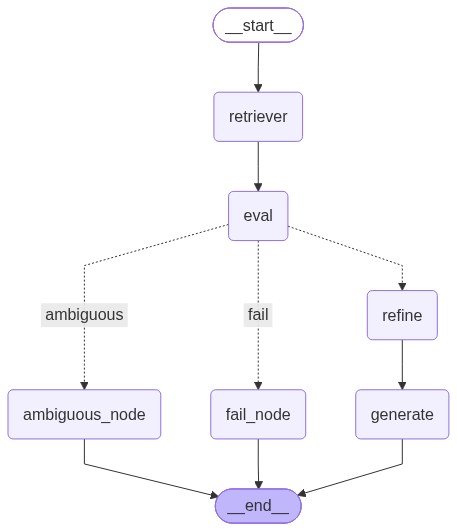

In [45]:
wf

In [46]:
rs=wf.invoke({'ques':'what is COCOMO Model?'})

In [47]:
print("\n",rs['answer'])


 From the document:

COCOMO (Constructive Cost Model) was proposed by Barry Boehm in 1981 and is based on the study of 63 projects. It is a software cost estimation (procedural cost estimate) model used to predict effort, cost, and schedule required for a software development project. COCOMO helps reliably predict project parameters such as size, effort, cost, time, and quality; its primary outcomes are effort and schedule.


In [49]:
rs['reason']

'Scored > 0.7'

In [40]:
print(rs['kept_strips'])

['Machine Learning Fundamentals Synthetic study material designed to test RAG chunking and retrieval.', 'The document intentionally places related but potentially misleading statements near each other.', 'A retrieval system should use the complete context rather than assuming every retrieved sentence describes the same concept.', 'What is gradient descent?', 'Gradient descent is an optimization algorithm used to minimize a loss function.', 'It repeatedly updates model parameters in the direction of the negative gradient.', 'The learning rate controls how large each update is.', 'A larger learning rate always makes training more accurate because the optimizer can reach the minimum faster.', 'In practice, the best learning rate depends on the model, data, and optimization problem.', 'Important clarification: the first sentence describes the standard purpose of gradient descent.', 'The statement that a larger learning rate always improves accuracy is intentionally misleading.', 'Related n

In [ ]:
print(rs['context'])